# K-Means Clustering- Customer Segmentation

The stages:
- Read and the understand the data.
- Clean the data
- Prepare the data for data modelling.
- Modelling.
- Final analyasis and recommendations.

In [192]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import datetime as dt

In [194]:
df=pd.read_excel("/Users/meghaprajapati/Downloads/2234674-case_study/data/retail.xlsx")

In [195]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [196]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [197]:
# basics of df
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## Cleaning the data:


In [199]:
df.isnull().sum()/len(df)*100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [200]:
# drop all rows having missing values in customer ID.

df=df.dropna(subset=["CustomerID"])
df.shape

(406829, 8)

In [201]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [202]:
df["Description"]=df["Description"].fillna(df["Description"].mode()[0])

/var/folders/zr/yf7yczb95nv_tkd0pg7hxjww0000gn/T/ipykernel_7906/2258279247.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Description"]=df["Description"].fillna(df["Description"].mode()[0])


In [203]:
df["Description"].mode()[0]

'WHITE HANGING HEART T-LIGHT HOLDER'

In [204]:
df.isnull().sum()/len(df)*100

InvoiceNo      0.0
StockCode      0.0
Description    0.0
Quantity       0.0
InvoiceDate    0.0
UnitPrice      0.0
CustomerID     0.0
Country        0.0
dtype: float64

In [205]:
# new column amount
df["Amount"]=df["Quantity"]*df["UnitPrice"]

/var/folders/zr/yf7yczb95nv_tkd0pg7hxjww0000gn/T/ipykernel_7906/2847057971.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Amount"]=df["Quantity"]*df["UnitPrice"]


In [206]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Amount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


## Preparing the data for modelling:

- R( Recency) : Number of days since the last purchase.
- F (Frequency): Number of transactions.
- M (Monetary): Total number of transactions (revenue contributed)

In [208]:
# monetary:
amount=df.groupby("CustomerID")["Amount"].sum()
amount=amount.reset_index()
amount

,CustomerID,Amount
0,12346.0,0.00
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40
...,...,...
4367,18280.0,180.60
4368,18281.0,80.82
4369,18282.0,176.60
4370,18283.0,2094.88


In [209]:
# frequency

frequency=df.groupby("CustomerID")["InvoiceNo"].nunique()
frequency=frequency.reset_index()
frequency

,CustomerID,InvoiceNo
0,12346.0,2
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1
...,...,...
4367,18280.0,1
4368,18281.0,1
4369,18282.0,3
4370,18283.0,16


In [210]:
# merge the two dfs

grouped_df=pd.merge(amount,frequency,on="CustomerID",how="inner")
grouped_df

,CustomerID,Amount,InvoiceNo
0,12346.0,0.00,2
1,12347.0,4310.00,7
2,12348.0,1797.24,4
3,12349.0,1757.55,1
4,12350.0,334.40,1
...,...,...,...
4367,18280.0,180.60,1
4368,18281.0,80.82,1
4369,18282.0,176.60,3
4370,18283.0,2094.88,16


In [211]:
# recency:

max_date=max(df["InvoiceDate"])
max_date

Timestamp('2011-12-09 12:50:00')

In [212]:
# compute the diff

df["difference"]=max_date-df["InvoiceDate"]
df

/var/folders/zr/yf7yczb95nv_tkd0pg7hxjww0000gn/T/ipykernel_7906/1864247131.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["difference"]=max_date-df["InvoiceDate"]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Amount,difference
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,373 days 04:24:00
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,373 days 04:24:00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,0 days 00:00:00
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,0 days 00:00:00
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,0 days 00:00:00
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,0 days 00:00:00


In [213]:
# recency:

last_purchase=df.groupby("CustomerID")["difference"].min()
last_purchase=last_purchase.reset_index()
last_purchase.head()

,CustomerID,difference
0,12346.0,325 days 02:33:00
1,12347.0,1 days 20:58:00
2,12348.0,74 days 23:37:00
3,12349.0,18 days 02:59:00
4,12350.0,309 days 20:49:00


In [214]:
#merge 

grouped_df=pd.merge(grouped_df,last_purchase,on="CustomerID",how="inner")
grouped_df.columns=["CustomerID","Amount","Frequency","Recency"]
grouped_df.head()

,CustomerID,Amount,Frequency,Recency
0,12346.0,0.00,2,325 days 02:33:00
1,12347.0,4310.00,7,1 days 20:58:00
2,12348.0,1797.24,4,74 days 23:37:00
3,12349.0,1757.55,1,18 days 02:59:00
4,12350.0,334.40,1,309 days 20:49:00


In [234]:
grouped_df["Recency"]=grouped_df["Recency"].dt.days

In [236]:
grouped_df

,CustomerID,Amount,Frequency,Recency
0,12346.0,0.00,2,325
1,12347.0,4310.00,7,1
2,12348.0,1797.24,4,74
3,12349.0,1757.55,1,18
4,12350.0,334.40,1,309
...,...,...,...,...
4367,18280.0,180.60,1,277
4368,18281.0,80.82,1,180
4369,18282.0,176.60,3,7
4370,18283.0,2094.88,16,3


# Data Modelling:

In [239]:
# rescaling the data:

rs_df=grouped_df[["Amount","Frequency","Recency"]]

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans



In [245]:
scaler=StandardScaler()
rs_df=scaler.fit_transform(rs_df)
rs_df=pd.DataFrame(rs_df)
rs_df.columns=["Amount","Frequency","Recency"]
rs_df.head()

,Amount,Frequency,Recency
0,-0.231001,-0.329362,2.322023
1,0.293432,0.206102,-0.893733
2,-0.012316,-0.115176,-0.169196
3,-0.017146,-0.436455,-0.725005
4,-0.190312,-0.436455,2.163220


# Modelling:

In [248]:
# K-means with random value of K

kmeans=KMeans(n_clusters=4,max_iter=50)
kmeans.fit(rs_df)

,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,50
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [250]:
kmeans.labels_  # data belonging to different types of clusters.

array([1, 0, 0, ..., 0, 0, 0], dtype=int32)

## Finding the optimal value of K
### Elbow Method:


[9204.080477314317, 5530.489552652463, 4143.448031283209, 3037.977902763231, 2383.313122630173, 1906.0398474704862, 1593.6352548771001, 1513.8239283409835, 1240.9845819236873]


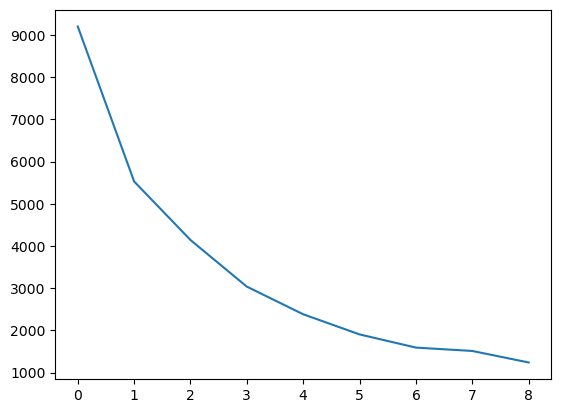

In [256]:
#itra_cluster_distance(Sum of Sqaured Distance within the cluster)

ssd=[]
range_n_clusters=[2,3,4,5,6,7,8,9,10]

for num_clusters in range_n_clusters:
    kmeans=KMeans(n_clusters=num_clusters,max_iter=50)
    kmeans.fit(rs_df)
    ssd.append(kmeans.inertia_)


#plotting the SSD for each n_clusters
print(ssd)
plt.plot(ssd)

In [258]:
# ftting the model with correct number of clusters
# K-means with random value of K

kmeans=KMeans(n_clusters=3,max_iter=50)
kmeans.fit(rs_df)
kmeans.labels_

array([2, 1, 1, ..., 1, 1, 1], dtype=int32)

In [266]:
# assignind the labels in the df
grouped_df["Cluster_id"]=kmeans.labels_
grouped_df

,CustomerID,Amount,Frequency,Recency,Cluster_id
0,12346.0,0.00,2,325,2
1,12347.0,4310.00,7,1,1
2,12348.0,1797.24,4,74,1
3,12349.0,1757.55,1,18,1
4,12350.0,334.40,1,309,2
...,...,...,...,...,...
4367,18280.0,180.60,1,277,2
4368,18281.0,80.82,1,180,2
4369,18282.0,176.60,3,7,1
4370,18283.0,2094.88,16,3,1


In [268]:
grouped_df[grouped_df["Cluster_id"]==2]

,CustomerID,Amount,Frequency,Recency,Cluster_id
0,12346.0,0.00,2,325,2
4,12350.0,334.40,1,309,2
6,12353.0,89.00,1,203,2
7,12354.0,1079.40,1,231,2
8,12355.0,459.40,1,213,2
...,...,...,...,...,...
4353,18260.0,2595.00,8,172,2
4355,18262.0,149.48,1,139,2
4359,18269.0,138.90,2,357,2
4367,18280.0,180.60,1,277,2


<Axes: xlabel='Cluster_id', ylabel='Amount'>

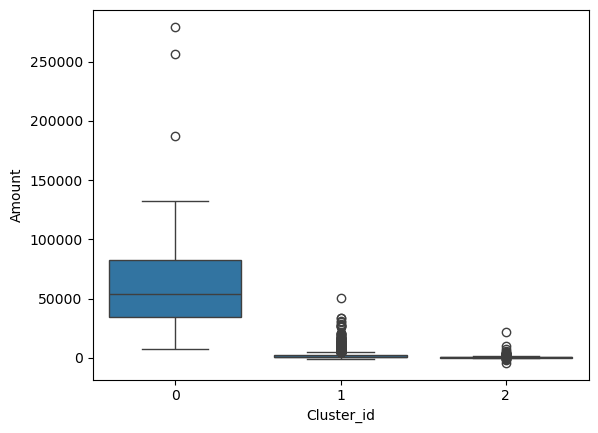

In [272]:
# plot the graph

sns.boxplot(x="Cluster_id",y="Amount",data=grouped_df)

# Observations:

- Cluster 0 represents high monetary customers
- cluster 2 and 1 has high overlap.

<Axes: xlabel='Cluster_id', ylabel='Frequency'>

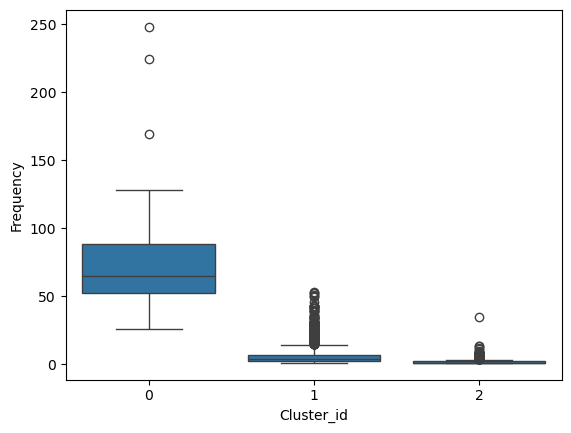

In [275]:
sns.boxplot(x="Cluster_id",y="Frequency",data=grouped_df)

# Observations:

- Cluster 0 represents high frequency customers
- cluster 2 and 1 has high overlap.

<Axes: xlabel='Cluster_id', ylabel='Recency'>

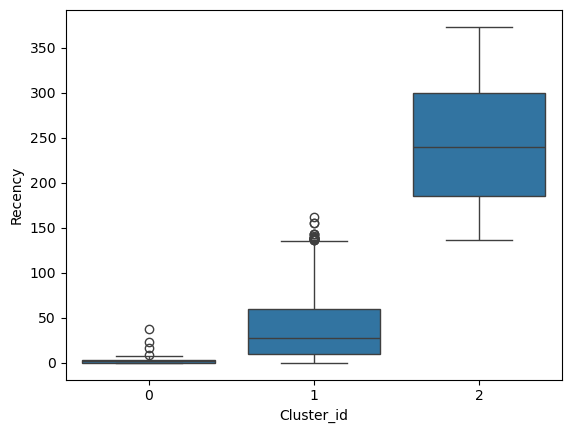

In [278]:
sns.boxplot(x="Cluster_id",y="Recency",data=grouped_df)

# Observation:

- Cluster 2 represents low rececy customers.
- Cluster 0 represents least recent.

In [ ]:
# remove the outliers from the grouped_df data
# rescale it again
# apply kmeans with random K
#choose the optimal value of K with elbow
# visualize the observation using box plot